# Quickstart: ECMWF IFS ENS forecasts, virtual - dynamical.org Icechunk Zarr

ECMWF IFS ENS is a 51-member global ensemble weather forecast. These datasets provide its surface and pressure-level fields, at 0.25 degree from April 2024 and 0.1 degree from October 2026.

The 6 day forecasts update every 6 hours, the 15 day forecasts every 12 hours.

These virtual datasets are optimized for spatial (map) access. For time series at a point, the [ECMWF IFS ENS forecast, 15 day, 0.25 degree](https://dynamical.org/catalog/ecmwf-ifs-ens-forecast-15-day-0-25-degree/) dataset is faster.

Dataset documentation:
- 6 day, 0.25 degree: https://dynamical.org/catalog/ecmwf-ifs-ens-forecast-6-day-0-25-degree-virtual/
- 15 day, 0.25 degree: https://dynamical.org/catalog/ecmwf-ifs-ens-forecast-15-day-0-25-degree-virtual/
- 6 day, 0.1 degree: https://dynamical.org/catalog/ecmwf-ifs-ens-forecast-6-day-0-1-degree-virtual/
- 15 day, 0.1 degree: https://dynamical.org/catalog/ecmwf-ifs-ens-forecast-15-day-0-1-degree-virtual/

Dataset licenced [CC-BY-4.0](https://creativecommons.org/licenses/by/4.0/) and [ECMWF Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install 'dynamical-catalog>=1.0.0' cartopy

In [2]:
# TEMPORARY: these datasets are not in the dynamical.org catalog yet, so this cell opens their
# Icechunk stores directly. Once they are published, it becomes dynamical_catalog.open(...) calls.
import icechunk
import xarray as xr


def open_virtual(dataset_id, **kwargs):
    # Chunks reference ECMWF's open data on Google Cloud and AWS, read anonymously.
    authorize = icechunk.containers_credentials(
        {
            "gs://ecmwf-open-data/": icechunk.gcs_credentials(anonymous=True),
            "s3://ecmwf-forecasts/": icechunk.s3_anonymous_credentials(),
        }
    )
    storage = icechunk.s3_storage(
        bucket="dynamical-ecmwf-ifs-ens", prefix=f"{dataset_id}/v0.1.0.icechunk", region="us-west-2", anonymous=True
    )
    repo = icechunk.Repository.open(storage, authorize_virtual_chunk_access=authorize)
    return xr.open_zarr(repo.readonly_session("main").store, chunks=None, **kwargs)


forecast_6d = open_virtual("ecmwf-ifs-ens-forecast-6-day-0-25-degree-virtual")
forecast_15d = open_virtual("ecmwf-ifs-ens-forecast-15-day-0-25-degree-virtual")
forecast_6d_pressure = open_virtual("ecmwf-ifs-ens-forecast-6-day-0-25-degree-virtual", group="pressure_level")
forecast_6d_0p1 = open_virtual("ecmwf-ifs-ens-forecast-6-day-0-1-degree-virtual")
forecast_15d_0p1 = open_virtual("ecmwf-ifs-ens-forecast-15-day-0-1-degree-virtual")
forecast_15d

<xarray.Dataset> Size: 4PB
Dimensions:                                                      (
                                                                  init_time: 1910,
                                                                  lead_time: 85,
                                                                  ensemble_member: 51,
                                                                  latitude: 721,
                                                                  longitude: 1440)
Coordinates:
  * init_time                                                    (init_time) datetime64[ns] 15kB ...
    expected_forecast_length                                     (init_time) timedelta64[us] 15kB ...
  * lead_time                                                    (lead_time) timedelta64[us] 680B ...
    valid_time                                                   (init_time, lead_time) datetime64[ns] 1MB ...
  * ensemble_member                                              (ensemble_member) int16 102B ...
  * latitude                                                     (latitude) float64 6kB ...
  * longitude                                                    (longitude) float64 12kB ...
    spatial_ref                                                  int64 8B ...
Data variables: (12/55)
    categorical_precipitation_type_surface                       (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    convective_precipitation_run_total_surface                   (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    downward_long_wave_radiation_run_total_surface               (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    downward_short_wave_radiation_run_total_surface              (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    geopotential_height_surface                                  (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    dew_point_temperature_2m                                     (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    ...                                                           ...
    total_precipitation_run_total_surface                        (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    volumetric_soil_moisture_layer_1                             (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    volumetric_soil_moisture_layer_4                             (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    wind_gust_10m                                                (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    wind_v_10m                                                   (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
    wind_v_100m                                                  (init_time, lead_time, ensemble_member, latitude, longitude) float64 69TB ...
Attributes:
    dataset_id:           ecmwf-ifs-ens-forecast-15-day-0-25-degree-virtual
    dataset_version:      0.1.0
    name:                 ECMWF IFS ENS forecast, 15 day, 0.25 degree, virtual
    description:          Ensemble weather forecasts from the ECMWF Integrate...
    attribution:          ECMWF IFS ENS forecast data processed by dynamical....
    license:              CC-BY-4.0
    spatial_domain:       Global
    spatial_resolution:   0.25 degrees (~20km)
    time_domain:          Forecasts initialized 2024-04-01 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 12 hours
    forecast_domain:      Forecast lead time 0-360 hours (0-15 days) ahead
    forecast_resolution:  Forecast step 0-144 hours: 3 hourly, 144-360 hours:...

Each `init_time` is a model run with 51 `ensemble_member`s; member 0 is the control. Variables on pressure levels live in the `pressure_level` group.

In [3]:
forecast_6d_pressure

<xarray.Dataset> Size: 11PB
Dimensions:                   (init_time: 3820, lead_time: 49,
                               ensemble_member: 51, latitude: 721,
                               longitude: 1440, pressure_level: 14)
Coordinates:
  * init_time                 (init_time) datetime64[ns] 31kB 2024-04-01 ... ...
    expected_forecast_length  (init_time) timedelta64[us] 31kB ...
  * lead_time                 (lead_time) timedelta64[us] 392B 00:00:00 ... 6...
    valid_time                (init_time, lead_time) datetime64[ns] 1MB ...
  * ensemble_member           (ensemble_member) int16 102B 0 1 2 3 ... 48 49 50
  * latitude                  (latitude) float64 6kB 90.0 89.75 ... -89.75 -90.0
  * longitude                 (longitude) float64 12kB -180.0 -179.8 ... 179.8
  * pressure_level            (pressure_level) int64 112B 10 50 100 ... 925 1000
    spatial_ref               int64 8B ...
Data variables:
    geopotential              (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    divergence                (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    geopotential_height       (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    relative_humidity         (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    relative_vorticity        (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    temperature               (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    vertical_velocity         (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    specific_humidity         (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    wind_v                    (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
    wind_u                    (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 1PB ...
Attributes:
    dataset_id:           ecmwf-ifs-ens-forecast-6-day-0-25-degree-virtual
    dataset_version:      0.1.0
    name:                 ECMWF IFS ENS forecast, 6 day, 0.25 degree, virtual
    description:          Ensemble weather forecasts from the ECMWF Integrate...
    attribution:          ECMWF IFS ENS forecast data processed by dynamical....
    license:              CC-BY-4.0
    spatial_domain:       Global
    spatial_resolution:   0.25 degrees (~20km)
    time_domain:          Forecasts initialized 2024-04-01 00:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-144 hours (0-6 days) ahead
    forecast_resolution:  3 hourly

## How strong would Storm Éowyn's gusts be?

[Storm Éowyn](https://en.wikipedia.org/wiki/Storm_%C3%89owyn) brought record gusts of about 51 m s⁻¹ (183 km/h) to Mace Head, Ireland, on the morning of 24 January 2025. Here is every member of the run three days earlier.

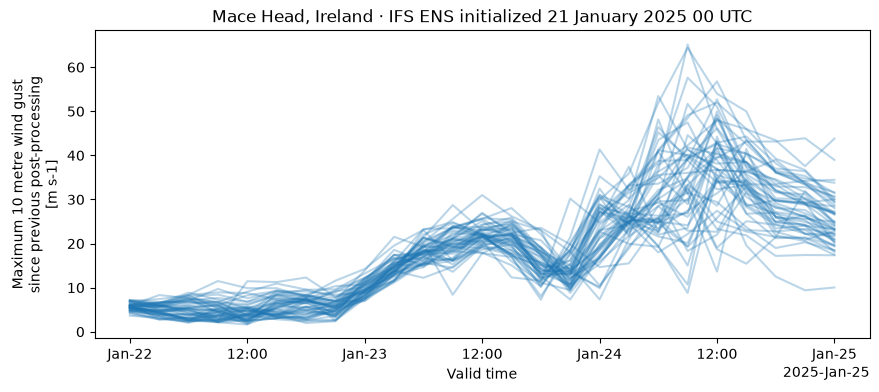

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

(
    forecast_6d["wind_gust_10m"]
    .sel(init_time="2025-01-21T00", lead_time=pd.timedelta_range("24h", "96h", freq="3h"))
    .sel(latitude=53.33, longitude=-9.90, method="nearest")
    .plot(x="valid_time", hue="ensemble_member", add_legend=False, color="tab:blue", alpha=0.3, size=4, aspect=2.5)
)
plt.title("Mace Head, Ireland · IFS ENS initialized 21 January 2025 00 UTC");

## Where would Milton come ashore?

[Hurricane Milton](https://en.wikipedia.org/wiki/Hurricane_Milton) made landfall near Siesta Key, Florida, at about 00:30 UTC on 10 October 2024. These are the first 20 members' 84 hour forecasts just before landfall.

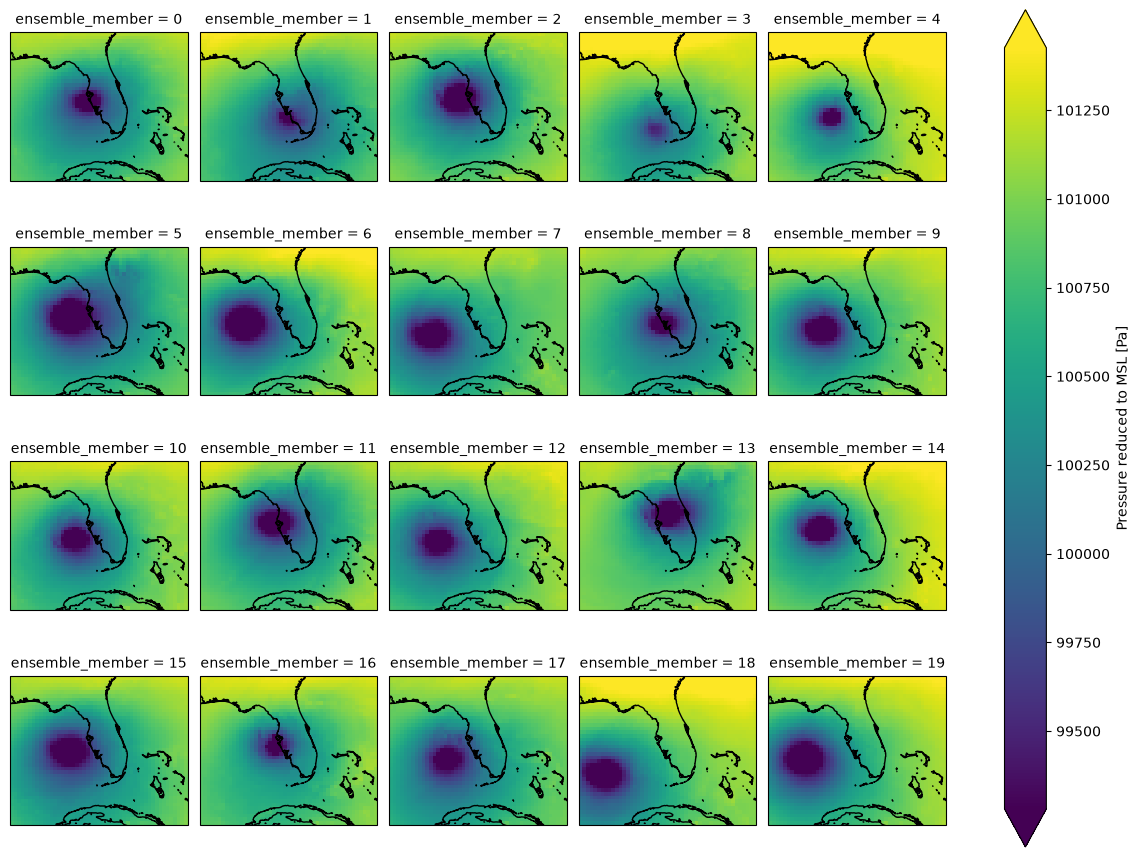

In [5]:
import cartopy.crs as ccrs

milton = (
    forecast_6d["pressure_reduced_to_mean_sea_level"]
    .sel(init_time="2024-10-06T12", lead_time="84h", ensemble_member=slice(0, 19))
    .sel(latitude=slice(32, 22), longitude=slice(-88, -76))
)

grid = milton.plot(
    col="ensemble_member", col_wrap=5, transform=ccrs.PlateCarree(),
    subplot_kws={"projection": ccrs.PlateCarree()}, robust=True, size=2.2,
)
for ax in grid.axs.flat:
    ax.coastlines()

## How often do the forecasts start, and how far do they reach?

The 6 day datasets start a forecast every 6 hours. The 15 day datasets carry only the 00 and 12 UTC runs.

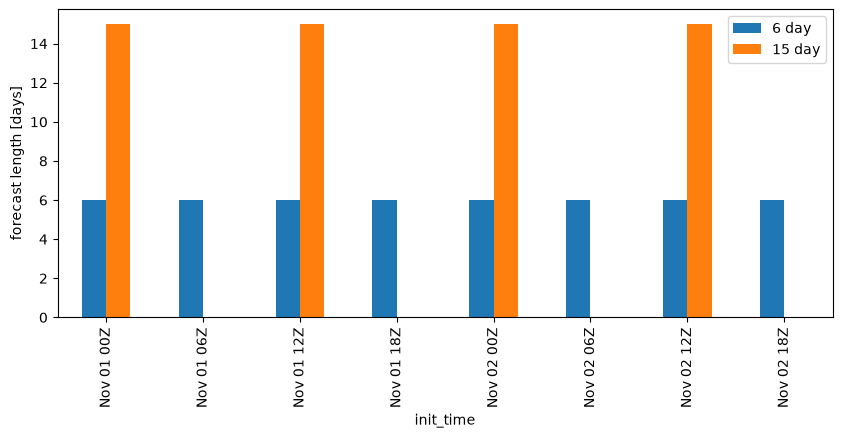

In [6]:
window = slice("2026-11-01T00", "2026-11-02T18")
lengths = pd.DataFrame(
    {
        "6 day": forecast_6d_0p1["expected_forecast_length"].sel(init_time=window).to_series(),
        "15 day": forecast_15d_0p1["expected_forecast_length"].sel(init_time=window).to_series(),
    }
) / pd.Timedelta("1D")
lengths.index = lengths.index.strftime("%b %d %HZ")
_ = lengths.plot.bar(figsize=(10, 4), ylabel="forecast length [days]")

## What detail does the 0.1 degree grid show?

[Storm Charles](https://en.wikipedia.org/wiki/2026%E2%80%9327_European_windstorm_season) swept past Madeira and the Canary Islands on 10 and 11 November 2026. Here are the control member's gusts over the Canary Islands at both resolutions, 24 hours into the 10 November 00 UTC run.

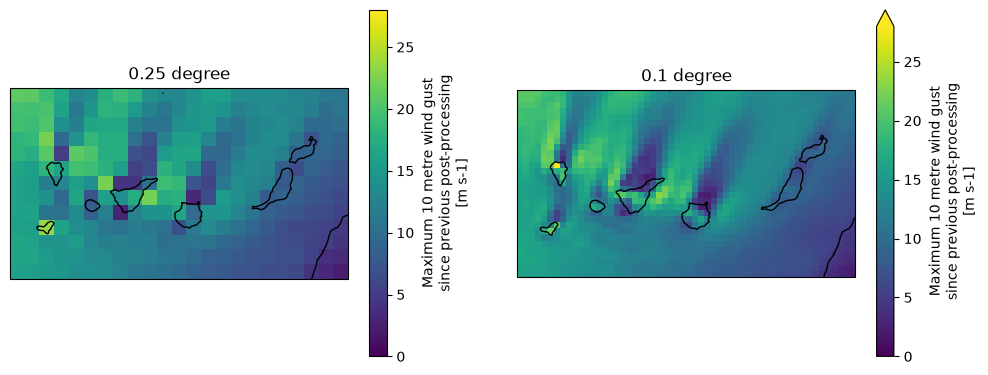

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), subplot_kw={"projection": ccrs.PlateCarree()})
for ax, (resolution, ds) in zip(axes, {"0.25 degree": forecast_6d, "0.1 degree": forecast_6d_0p1}.items()):
    (
        ds["wind_gust_10m"]
        .sel(init_time="2026-11-10T00", lead_time="24h", ensemble_member=0)
        .sel(latitude=slice(30, 27), longitude=slice(-18.5, -13))
        .plot(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=28)
    )
    ax.coastlines("10m")
    ax.set_title(resolution)

## How sure was the ensemble of the cut-off low behind the Valencia floods?

A cut-off low settled over southern Spain at the end of October 2024 and fed the storms behind the [catastrophic Valencia floods](https://en.wikipedia.org/wiki/2024_Spanish_floods) of 29 October. Each line is one member's 5640 m contour of 500 hPa geopotential height, in the run initialized 26 October.

In [8]:
height = (
    forecast_6d_pressure["geopotential_height"]
    .sel(init_time="2024-10-26T00", lead_time=pd.timedelta_range("0h", "120h", freq="6h"), pressure_level=500)
    .sel(latitude=slice(55, 25), longitude=slice(-25, 15))
    .load()
)

In [9]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(7, 5), dpi=70, subplot_kw={"projection": ccrs.PlateCarree()})


def update(i):
    ax.clear()
    ax.coastlines()
    frame = height.isel(lead_time=i)
    for member in frame.ensemble_member:
        frame.sel(ensemble_member=member).plot.contour(
            ax=ax, levels=[5640], colors="tab:blue", linewidths=0.6, transform=ccrs.PlateCarree()
        )
    ax.set_title(f"500 hPa, 51 members · {frame.valid_time.dt.strftime('%d %b %H UTC').item()}")


anim = FuncAnimation(fig, update, frames=height.sizes["lead_time"], interval=300)
plt.close(fig)
HTML(anim.to_jshtml())

## How fast did the cold air reach New Orleans?

On 21 January 2025 the [Gulf Coast blizzard](https://en.wikipedia.org/wiki/2025_Gulf_Coast_blizzard) brought up to 10 inches of snow to New Orleans. Each line is one member's temperature profile over the city, in the run initialized 19 January.

In [10]:
profiles = (
    forecast_6d_pressure["temperature"]
    .sel(init_time="2025-01-19T00", lead_time=pd.timedelta_range("30h", "66h", freq="6h"), pressure_level=[500, 700, 850, 925, 1000])
    .sel(latitude=29.95, longitude=-90.07, method="nearest")
    .transpose("lead_time", "pressure_level", "ensemble_member")
    .load()
)

In [11]:
fig, ax = plt.subplots(figsize=(4.5, 5), dpi=70)
lines = ax.plot(profiles.isel(lead_time=0), profiles.pressure_level, color="tab:blue", alpha=0.4)
ax.axvline(0, color="black")
ax.set(xlim=(-20, 10), xlabel="Temperature [°C]", ylabel="Pressure level [hPa]")
ax.invert_yaxis()
fig.tight_layout()


def update(i):
    frame = profiles.isel(lead_time=i)
    for line, member in zip(lines, frame.T.values):
        line.set_xdata(member)
    ax.set_title(f"New Orleans, 51 members · {frame.valid_time.dt.strftime('%d %b %H UTC').item()}")


anim = FuncAnimation(fig, update, frames=profiles.sizes["lead_time"], interval=400)
plt.close(fig)
HTML(anim.to_jshtml())

## Community challenge

- Around mountains and coastlines, are the 0.1 degree gusts and precipitation closer to station observations than the 0.25 degree ones, and where?
- Do the 06 and 18 UTC 6 day runs improve on the 00 and 12 UTC runs from six hours earlier, and for how many days?
- For the same storms, how well does ensemble spread track forecast error in IFS ENS and [ECMWF AIFS ENS](https://dynamical.org/catalog/ecmwf-aifs-ens-forecast/)?